# EcoPredict — Evaluación de XGBoost para residuos sólidos domiciliarios

Experimentos con registros distritales de la provincia de Lima (2019–2024): comparación de regresores, variables históricas, evaluación temporal, ablación de características, análisis SHAP y errores distritales.

**Datos de entrada:** `dataset3_proporcion.csv` (archivo procesado). La evaluación principal incluye variables contemporáneas de población y generación per cápita; por ello, sus resultados representan estimación retrospectiva y no, por sí solos, un pronóstico anticipado.

In [ ]:
%pip -q install xgboost shap scikit-learn pandas matplotlib openpyxl

In [ ]:
import sys, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from xgboost import XGBRegressor
import sklearn, xgboost, shap
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__, '| sklearn:',sklearn.__version__, '| xgboost:',xgboost.__version__, '| shap:',shap.__version__)


Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1 | xgboost: 3.4.1 | shap: 0.54.1


Para usar Google Drive en Colab, monta la unidad y ajusta `DATA_PATH` en la siguiente celda. Si ejecutas localmente o subes el CSV a Colab, colócalo junto al notebook.

## 1. Carga del dataset procesado original

In [ ]:
DATA_PATH = Path('dataset3_proporcion.csv')
if not DATA_PATH.exists():
    from pathlib import Path
    candidates = [Path('/content/dataset3_proporcion.csv'), Path('/content/drive/MyDrive/Colab Notebooks/dataset3_proporcion.csv')]
    DATA_PATH = next((p for p in candidates if p.exists()), DATA_PATH)
if not DATA_PATH.exists():
    raise FileNotFoundError(f'No se encontró {DATA_PATH}. Sube el CSV o configura DATA_PATH.')
raw = pd.read_csv(DATA_PATH, encoding='latin1', sep=';', low_memory=False)
raw.columns = raw.columns.astype(str).str.strip().str.upper()
print('Archivo:',DATA_PATH,'Dimensiones:',raw.shape)
assert all(x in raw.columns for x in ['PROVINCIA','DISTRITO','PERIODO','POB_TOTAL','POB_RURAL','GPC_DOM','QRESIDUOS_DOM'])
df = raw.loc[raw['PROVINCIA'].astype(str).str.strip().str.upper().eq('LIMA')].copy()
df = df.rename(columns={'PERIODO':'AÑO','GPC_DOM':'GPC'})
df['AÑO'] = pd.to_numeric(df['AÑO'], errors='coerce')
df = df[df['AÑO'].between(2019,2024)].copy()
df['DISTRITO'] = df['DISTRITO'].astype(str).str.strip().str.upper()
# Homologación de la denominación del distrito entre años
df['DISTRITO'] = df['DISTRITO'].replace({
    'MAGDALENA VIEJA': 'PUEBLO LIBRE'
})
df = df.drop(columns=['PROVINCIA','DEPARTAMENTO','REG_NAT','FECHA_CORTE','POB_URBANA','UBIGEO','N_SEC'], errors='ignore')
for x in df.columns.difference(['DISTRITO']):
    df[x] = pd.to_numeric(df[x], errors='coerce')
print('Lima:',df.shape,'Distritos:',df['DISTRITO'].nunique())
print(df.groupby('AÑO').size())
if df.duplicated(['DISTRITO','AÑO']).any():
    raise ValueError('Existen registros duplicados distrito-año: revisar fuente antes del modelado.')


## 2. Construcción de variables históricas

In [ ]:
columnas_composicion = [x for x in df.columns if x.startswith('QRESIDUOS_') and x != 'QRESIDUOS_DOM']
df[columnas_composicion] = df[columnas_composicion].fillna(0)
df = df.sort_values(['DISTRITO','AÑO']).reset_index(drop=True)
df['LAG1_TOTAL'] = df.groupby('DISTRITO')['QRESIDUOS_DOM'].shift(1)
df['LAG2_TOTAL'] = df.groupby('DISTRITO')['QRESIDUOS_DOM'].shift(2)
df['CRECIMIENTO_TOTAL'] = df['LAG1_TOTAL'] - df['LAG2_TOTAL']
df['ROLL_MEAN_2_TOTAL'] = df.groupby('DISTRITO')['QRESIDUOS_DOM'].transform(lambda x:x.shift(1).rolling(2,min_periods=1).mean())
columnas_comp_lag = []
for col in columnas_composicion:
    df[col+'_LAG1'] = df.groupby('DISTRITO')[col].shift(1)
    prop = col+'_PROP_LAG1'
    df[prop] = df[col+'_LAG1']/(df['LAG1_TOTAL']+1e-6)
    columnas_comp_lag.append(prop)
df = df.replace([np.inf,-np.inf],np.nan).dropna(subset=['LAG1_TOTAL','LAG2_TOTAL','CRECIMIENTO_TOTAL','ROLL_MEAN_2_TOTAL']+columnas_comp_lag)
print('Registros modelables:',len(df),'por año:',df.groupby('AÑO').size().to_dict())


Registros modelables: 172 por año: {2021: 43, 2022: 43, 2023: 43, 2024: 43}


## 3. Entrenamiento y comparación de algoritmos

In [ ]:
historicas = ['LAG1_TOTAL','LAG2_TOTAL','CRECIMIENTO_TOTAL','ROLL_MEAN_2_TOTAL']
contemporaneas = ['POB_TOTAL','POB_RURAL','GPC']
base = ['DISTRITO','AÑO']
features = base + contemporaneas + historicas + columnas_comp_lag
train = df['AÑO'].le(2022)
test = df['AÑO'].ge(2023)
print('Entrenamiento:',train.sum(),'Prueba:',test.sum())

def pipeline(tipo, cols):
    cat=['DISTRITO'] if 'DISTRITO' in cols else []
    numeric=[x for x in cols if x not in cat]
    if tipo=='SVR':
        prep=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),cat),('num',StandardScaler(),numeric)],sparse_threshold=0)
        estimator=SVR(C=100,epsilon=0.1)
    else:
        prep=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),cat),('num','passthrough',numeric)])
        estimator={'XGBoost':XGBRegressor(n_estimators=500,learning_rate=.05,max_depth=5,subsample=.9,colsample_bytree=.9,reg_alpha=.2,reg_lambda=1.5,random_state=42,objective='reg:squarederror'), 'Random Forest':RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1), 'Linear Regression':LinearRegression()}[tipo]
    return Pipeline([('prep',prep),('model',estimator)])

def metricas(y,p):
    return {'R2':r2_score(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'MAE':mean_absolute_error(y,p)}

comparacion=[]; ajustados={}; predicciones={}
for tipo in ['XGBoost','Random Forest','Linear Regression','SVR']:
    mod=pipeline(tipo,features)
    mod.fit(df.loc[train,features],df.loc[train,'QRESIDUOS_DOM'])
    p=mod.predict(df.loc[test,features])
    comparacion.append({'Modelo':tipo, **metricas(df.loc[test,'QRESIDUOS_DOM'],p)})
    ajustados[tipo]=mod; predicciones[tipo]=p
tabla_modelos=pd.DataFrame(comparacion)
display(tabla_modelos)


Entrenamiento: 86 Prueba: 86


,Modelo,R2,RMSE,MAE
0,XGBoost,0.983889,7.723812e+03,4.309619e+03
1,Random Forest,0.968971,1.071915e+04,5.263347e+03
2,Linear Regression,-3017.149709,3.343078e+06,1.661467e+06
3,SVR,-0.226391,6.738926e+04,4.324466e+04


## 4. Evaluación temporal

,Evaluación,Entrenamiento,Prueba,R2,RMSE,MAE
0,Fijo 2023,86,43,0.987520,6685.953805,3383.063901
1,Fijo 2024,86,43,0.980471,8637.856144,5236.174673
2,Reentrenado 2024,129,43,0.989246,6409.740809,3769.497733


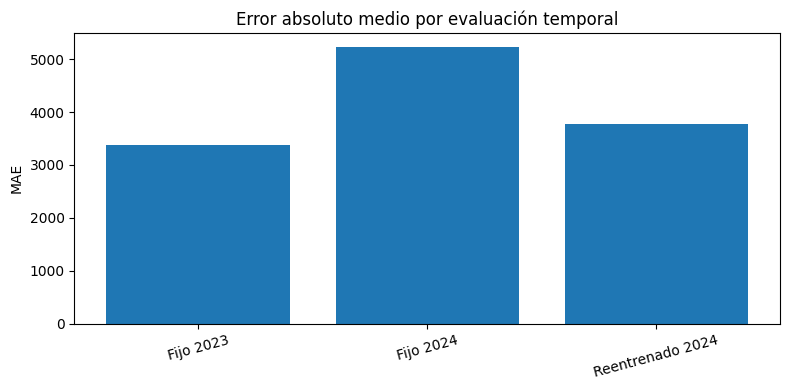

In [ ]:
temporal=[]
for nombre, tr, te in [
    ('Fijo 2023',df['AÑO'].le(2022),df['AÑO'].eq(2023)),
    ('Fijo 2024',df['AÑO'].le(2022),df['AÑO'].eq(2024)),
    ('Reentrenado 2024',df['AÑO'].le(2023),df['AÑO'].eq(2024))]:
    mod=pipeline('XGBoost',features)
    mod.fit(df.loc[tr,features],df.loc[tr,'QRESIDUOS_DOM'])
    p=mod.predict(df.loc[te,features])
    temporal.append({'Evaluación':nombre,'Entrenamiento':int(tr.sum()),'Prueba':int(te.sum()),**metricas(df.loc[te,'QRESIDUOS_DOM'],p)})
tabla_temporal=pd.DataFrame(temporal)
display(tabla_temporal)
plt.figure(figsize=(8,4));plt.bar(tabla_temporal['Evaluación'],tabla_temporal['MAE']);plt.ylabel('MAE');plt.title('Error absoluto medio por evaluación temporal');plt.xticks(rotation=15);plt.tight_layout();plt.savefig('fig_temporal.png',dpi=180);plt.show()


## 5. Ablación de grupos de variables

,Configuración,R2,RMSE,MAE
0,Full,0.983889,7723.811787,4309.619287
1,No lagged composition,0.985699,7277.072252,3722.908998
2,No same-year population/GPC,0.981580,8258.906596,4902.300371
3,Lag features only,0.979116,8793.919396,4868.596690
4,No temporal total features,0.983039,7924.959074,4744.148584


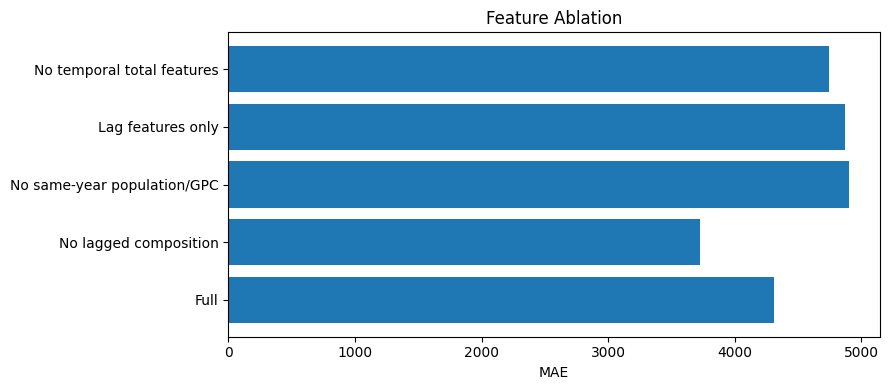

In [ ]:
grupos={
    'Full': features,
    'No lagged composition': base + contemporaneas + historicas,
    'No same-year population/GPC': base + historicas + columnas_comp_lag,
    'Lag features only': base + historicas,
    'No temporal total features': base + contemporaneas + columnas_comp_lag
}
ablacion=[]
for nombre, columnas in grupos.items():
    mod=pipeline('XGBoost',columnas)
    mod.fit(df.loc[train,columnas],df.loc[train,'QRESIDUOS_DOM'])
    p=mod.predict(df.loc[test,columnas])
    ablacion.append({'Configuración':nombre,**metricas(df.loc[test,'QRESIDUOS_DOM'],p)})
tabla_ablacion=pd.DataFrame(ablacion)
display(tabla_ablacion)
plt.figure(figsize=(9,4));plt.barh(tabla_ablacion['Configuración'],tabla_ablacion['MAE']);plt.xlabel('MAE');plt.title('Feature Ablation');plt.tight_layout();plt.savefig('fig_ablacion.png',dpi=180);plt.show()


## 6. Interpretabilidad con SHAP

,Variable,SHAP_abs_medio
44,num__POB_TOTAL,27759.257812
47,num__LAG1_TOTAL,15915.110352
48,num__LAG2_TOTAL,4320.202148
31,cat__DISTRITO_SAN JUAN DE LURIGANCHO,1361.998413
46,num__GPC,581.988525
69,num__QRESIDUOS_TETRABRICK_PROP_LAG1,293.316589
50,num__ROLL_MEAN_2_TOTAL,271.598663
62,num__QRESIDUOS_VIDRIOS_OTROS_PROP_LAG1,263.770630
57,num__QRESIDUOS_CARTON_BLANCO_PROP_LAG1,157.233810
49,num__CRECIMIENTO_TOTAL,90.850273


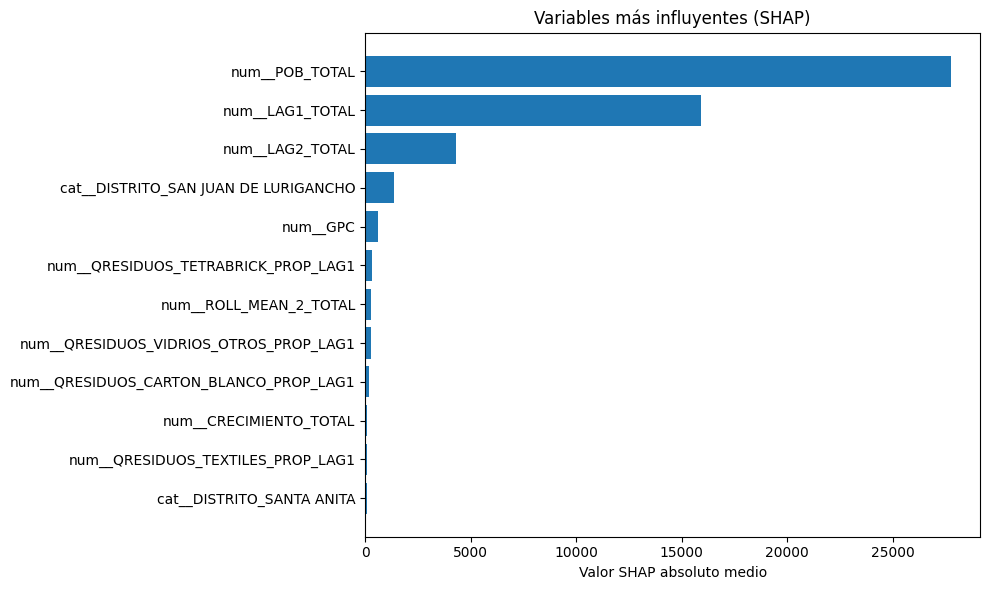

In [ ]:
xgb = ajustados['XGBoost']
Xte = xgb.named_steps['prep'].transform(df.loc[test,features])
if hasattr(Xte,'toarray'): Xte=Xte.toarray()
fnames=xgb.named_steps['prep'].get_feature_names_out()
explainer=shap.TreeExplainer(xgb.named_steps['model'])
shap_values=explainer.shap_values(Xte)
importancias=np.abs(np.asarray(shap_values)).mean(axis=0)
tabla_shap=pd.DataFrame({'Variable':fnames,'SHAP_abs_medio':importancias}).sort_values('SHAP_abs_medio',ascending=False)
display(tabla_shap.head(15))
top=tabla_shap.head(12).iloc[::-1]
plt.figure(figsize=(10,6));plt.barh(top['Variable'],top['SHAP_abs_medio']);plt.xlabel('Valor SHAP absoluto medio');plt.title('Variables más influyentes (SHAP)');plt.tight_layout();plt.savefig('fig_shap.png',dpi=180);plt.show()


## 7. Errores por distrito

,DISTRITO,AÑO,QRESIDUOS_DOM,Predicho,Error,Error_abs,Error_pct
209,SAN MARTIN DE PORRES,2024,188023.95,220288.078125,32264.128125,32264.128125,17.159584
107,LURIGANCHO,2024,87417.96,60347.320312,-27070.639688,27070.639688,30.966909
29,CARABAYLLO,2024,128675.64,112218.460938,-16457.179062,16457.179062,12.789662
83,LA VICTORIA,2024,52091.89,37811.964844,-14279.925156,14279.925156,27.412953
191,SAN JUAN DE LURIGANCHO,2024,286056.78,272674.718750,-13382.061250,13382.061250,4.678114
197,SAN JUAN DE MIRAFLORES,2024,119275.07,107113.570312,-12161.499688,12161.499688,10.196179
41,CHORRILLOS,2024,108441.51,96599.804688,-11841.705312,11841.705312,10.919901
89,LIMA,2024,70873.30,61489.496094,-9383.803906,9383.803906,13.240253
131,PACHACAMAC,2024,39815.50,31928.187500,-7887.312500,7887.312500,19.809653
71,JESUS MARIA,2024,16941.14,24632.933594,7691.793594,7691.793594,45.403046


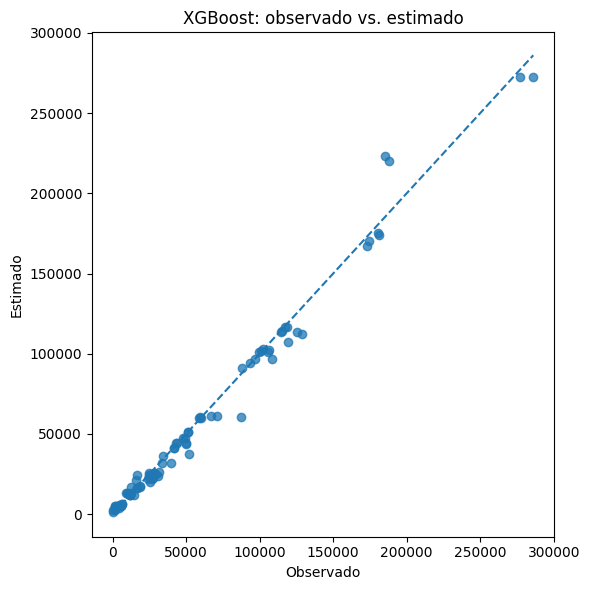

In [ ]:
detalle=df.loc[test,['DISTRITO','AÑO','QRESIDUOS_DOM']].copy()
detalle['Predicho']=predicciones['XGBoost']
detalle['Error']=detalle['Predicho']-detalle['QRESIDUOS_DOM']
detalle['Error_abs']=detalle['Error'].abs()
detalle['Error_pct']=np.where(detalle['QRESIDUOS_DOM'].abs()>1e-9,100*detalle['Error_abs']/detalle['QRESIDUOS_DOM'].abs(),np.nan)
display(detalle.loc[detalle['AÑO'].eq(2024)].sort_values('Error_abs',ascending=False).head(15))
plt.figure(figsize=(6,6));plt.scatter(detalle['QRESIDUOS_DOM'],detalle['Predicho'],alpha=.75);lim=[min(detalle['QRESIDUOS_DOM'].min(),detalle['Predicho'].min()),max(detalle['QRESIDUOS_DOM'].max(),detalle['Predicho'].max())];plt.plot(lim,lim,'--');plt.xlabel('Observado');plt.ylabel('Estimado');plt.title('XGBoost: observado vs. estimado');plt.tight_layout();plt.savefig('fig_observado_estimado.png',dpi=180);plt.show()


## 8. Exportación de resultados

In [ ]:
tabla_modelos.to_csv('tabla_modelos.csv',index=False)
tabla_temporal.to_csv('tabla_temporal.csv',index=False)
tabla_ablacion.to_csv('tabla_ablacion.csv',index=False)
tabla_shap.to_csv('tabla_shap.csv',index=False)
detalle.to_csv('tabla_errores_distrito.csv',index=False)
print('Tablas y figuras exportadas en el directorio de ejecución.')
